# 1. Physical question and complete measured path
Recover a conditional internal-stress history from the complete1003-point real author-distributed cyclic experiment. Total stress is observed;the four internal backstresses and isotropic contribution are latent model states. The sample index is loading order,not seconds. The supplied author-processed plastic strain is an observed input;no hidden elastic calibration is borrowed. This notebook selects the published classical random-start Nelder-Mead comparison rather than claiming to train the paper neural network.

### Required quantities and physical units
| Output | Shape | Unit/meaning |
|---|---|---|
| parameters |(1,12)|Ordered material parameters in table below |
| reconstruction |(1,1003,4)|Four signed backstresses inMPa;batch,sample,component |
| isotropic_stress |(1,1003)|SignedDk contribution inMPa;batch,sample |

| Parameter | Unit | Meaning |
|---|---|---|
| k0 |MPa|Initial yield magnitude |
| kappa1 |MPa|Isotropic saturation rate coefficient |
| kappa2 |inverseMPa|Inverse limiting yield magnitude |
| c1,c2,c3,c4 |inverse unit plastic strain(dimensionless)|Four hardening rates |
| a1,a2,a3,a4 |MPa|Four backstress saturation scales |
| abar |MPa|Fourth-component threshold scale |

The twelve-vector order is k0,kappa1,kappa2,c1,c2,c3,c4,a1,a2,a3,a4,abar. Inputs plastic/totalstrain aredimensionless;measuredstress isMPa. Loading sample is an orderedindex,notseconds. All outputs arefloat64.


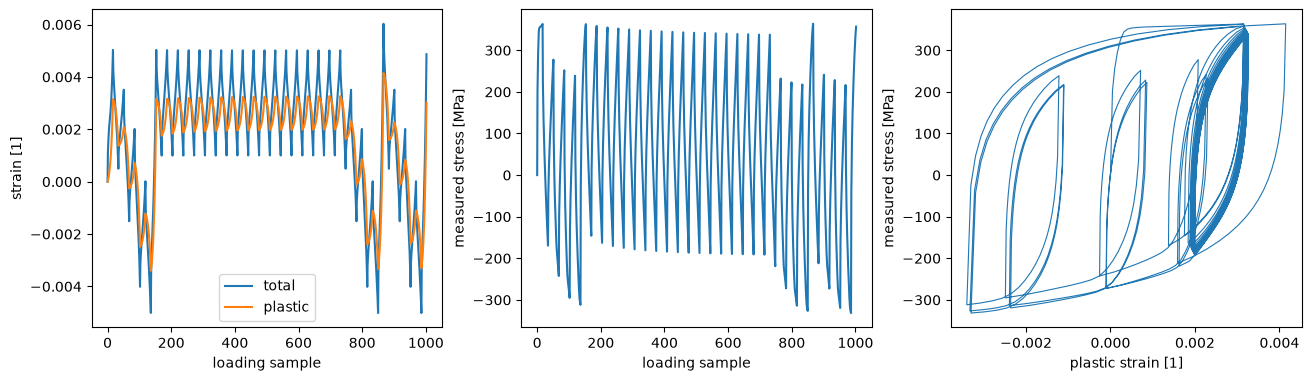

In [1]:
import os,sys,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from src.preprocessing import load
from src.physics_model import internal_states
from src.solvers import reconstruct
from src.visualization import show_fit
d=load();fig,axs=plt.subplots(1,3,figsize=(13,3.7),layout='constrained')
axs[0].plot(d['total_strain'],label='total');axs[0].plot(d['plastic_strain'],label='plastic');axs[0].set_xlabel('loading sample');axs[0].set_ylabel('strain [1]');axs[0].legend()
axs[1].plot(d['measured_stress']);axs[1].set_xlabel('loading sample');axs[1].set_ylabel('measured stress [MPa]')
axs[2].plot(d['plastic_strain'],d['measured_stress'],lw=.8);axs[2].set_xlabel('plastic strain [1]');axs[2].set_ylabel('measured stress [MPa]');plt.show()

# 2. Constitutive physics and independent upstream states
Let p accumulate absolute plastic-strain increments,D be the loading sign and k be yield magnitude. Ai=sqrt(2/3)ai and b=sqrt(2/3)abar scale the saturation/threshold parameters. Initially alpha=0,k=k0. The equations are
$$dk/dp=\sqrt{3/2}\kappa_1(1-\kappa_2 k),\quad d\alpha_i/dp=c_i(D A_i-\alpha_i),\quad i=1,2,3,$$
$$d\alpha_4/dp=c_4[D A_4-\mathrm{sign}(\alpha_4)\max(|\alpha_4|-b,0)],\quad S=\sqrt{3/2}\sum_i\alpha_i+Dk.$$
Every state is continuous at reversals. The fourth component has a linear threshold region between two exponential regimes. The implementation evaluates these closed forms by reversal segment. Independent fixtures were captured from the original author engine before cleaned validation;no cleaned function generated expected arrays.

In [2]:
with np.load('test/fixtures/upstream_states.npz') as f:
 a,k,s=internal_states(f['parameters'],f['plastic_strain']);print('Original-state maximum errors:',np.max(abs(a-f['output_backstress'])),np.max(abs(k-f['output_isotropic'])),np.max(abs(s-f['output_stress'])))
 assert np.allclose(a,f['output_backstress'],rtol=2e-12,atol=1e-10)

Original-state maximum errors: 0.0 0.0 0.0


# 3. Complete active reconstruction
The following cell performs all16independent starts and their Nelder-Mead refinements from raw observations. This takes approximately9minutes on a single CPU thread. The optimization uses no hidden fitted parameter vector or cached output. Its public target is full-curve stress MSE plus physical state consistency;the seed and finite optimizer trajectory are not part of the answer contract.

Actual fresh runtime seconds: 474.576817400055 start MSEs: [637.4818616949641, 621.6366089131828, 4344.1187390407, 5874.063302978364, 625.2852670898277, 4266.94985338701, 4914.378472201243, 3514.1078670498314, 646.7566468025117, 3356.486396159559, 1373.7331389332305, 617.2259631864328, 3786.6354841020584, 984.0892125057774, 3647.9526615098002, 3124.5397965640104]
Fresh positive parameters: [[6.58701964e+01 7.24920799e+02 1.71188238e-02 1.45281353e+04
  1.69283374e+03 5.90855084e+01 2.02945292e+01 7.10258440e+01
  1.45002755e+02 3.99926749e+00 1.53311842e+03 4.45244166e+02]]


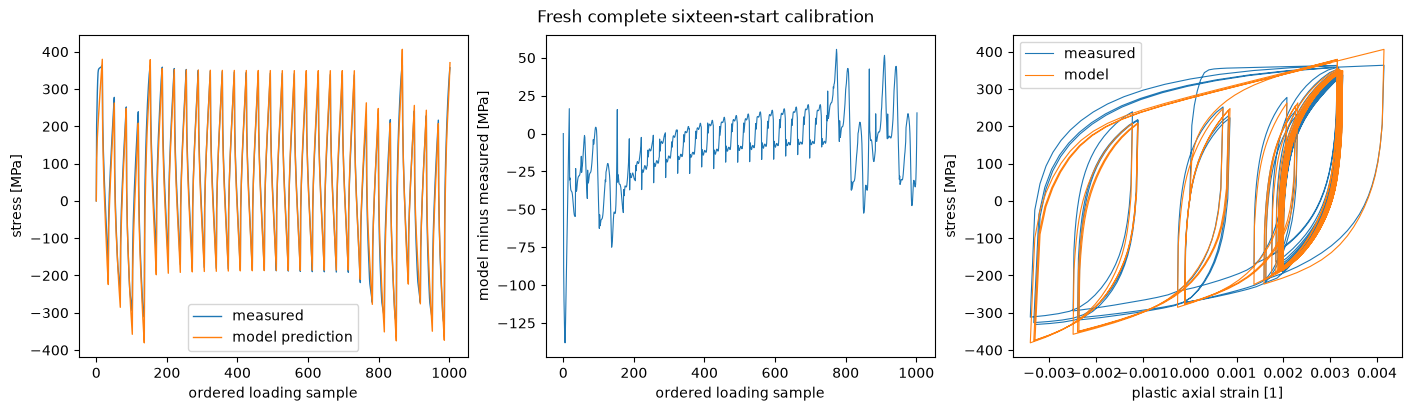

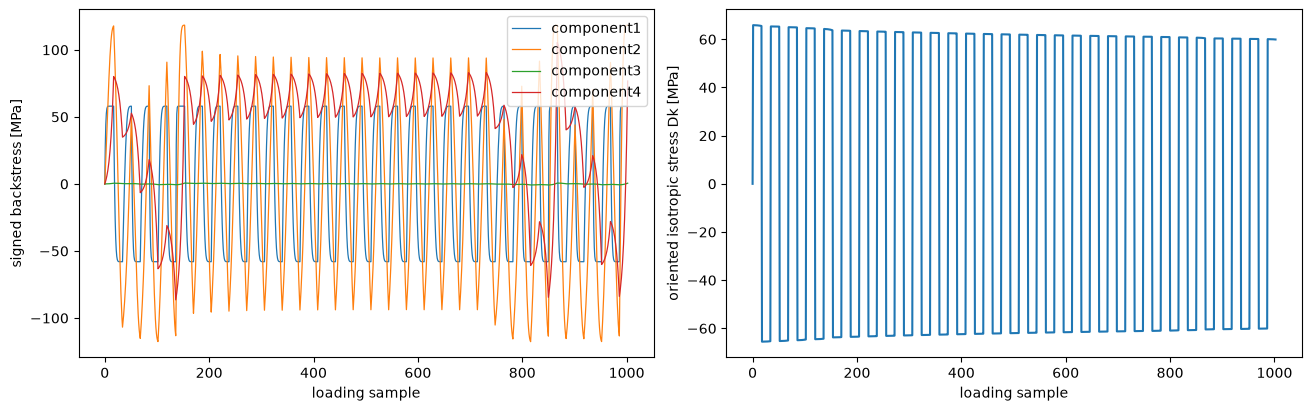

In [3]:
t=time.perf_counter();fresh,records=reconstruct(d);elapsed=time.perf_counter()-t
np.savez('output/reconstruction.npz',**fresh)
print('Actual fresh runtime seconds:',elapsed,'start MSEs:',[r['mse'] for r in records]);print('Fresh positive parameters:',fresh['parameters'])
show_fit(d,fresh,'Fresh complete sixteen-start calibration');plt.show()
fig,axs=plt.subplots(1,2,figsize=(13,4),layout='constrained')
for j in range(4):axs[0].plot(fresh['reconstruction'][0,:,j],label=f'component{j+1}',lw=.9)
axs[0].set_xlabel('loading sample');axs[0].set_ylabel('signed backstress [MPa]');axs[0].legend()
axs[1].plot(fresh['isotropic_stress'][0]);axs[1].set_xlabel('loading sample');axs[1].set_ylabel('oriented isotropic stress Dk [MPa]');plt.show()

# 4. Independent source fit and nonconvex optimization
The source comparison is the actually executed author random-start Nelder-Mead fit on these exact1003observations,not a paper-table number. Its eight-start run reached MSE621.758567MPa squared. A local eight-start port initially reached678.787766despite forward and initializer parity;small floating differences can change a long nonconvex optimizer trajectory. The local extended search improves the actual physical fit and retains the original threshold. Parameter or state identity is not scored. Optimizer spread is not a calibrated uncertainty distribution.

Independent upstream MSE: 621.7585672659311 fresh: 617.2259631864328


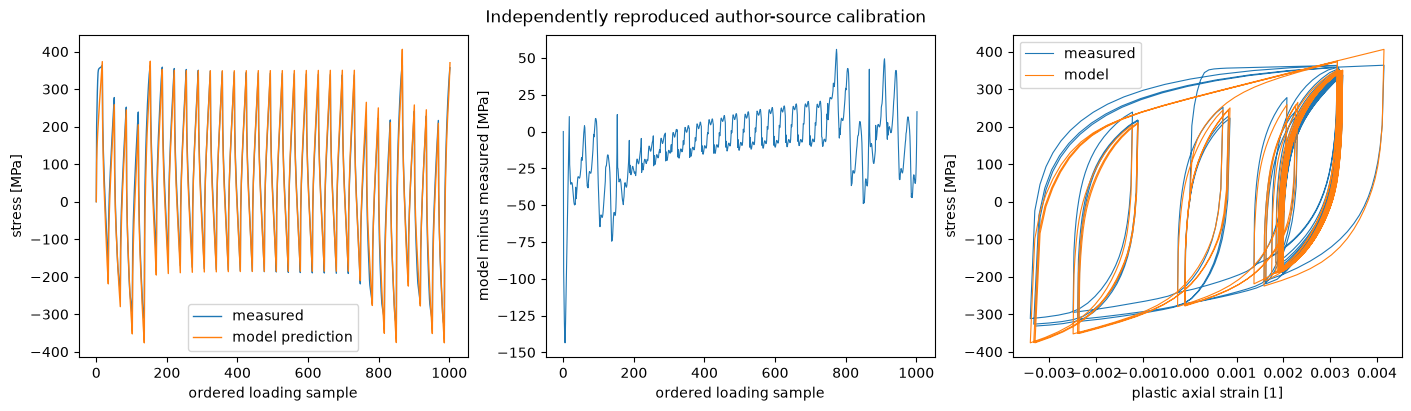

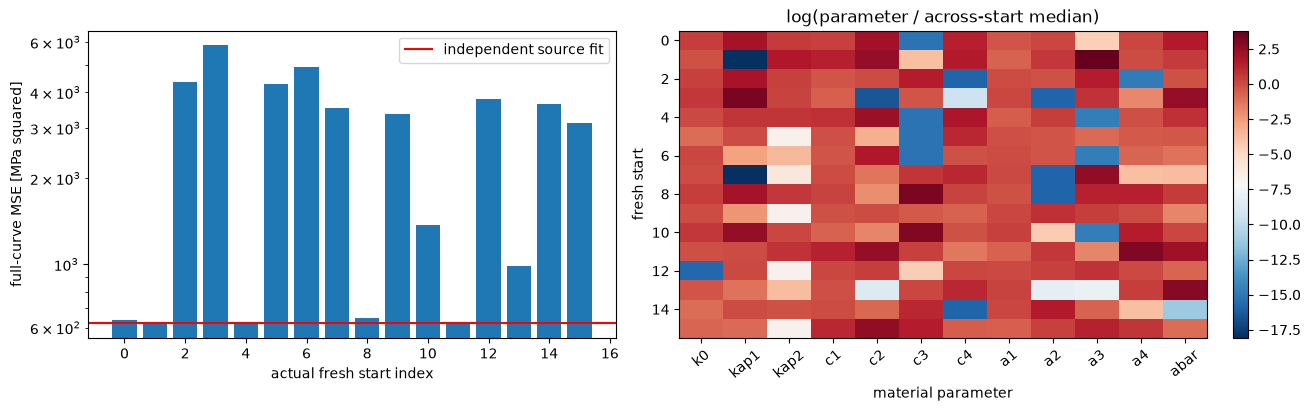

| Material parameter | Unit | Actual source | Fresh local |
|---|---|---:|---:|
| k0 | MPa | 52.53346215 | 65.87019639 |
| kappa1 | MPa | 19.93705273 | 724.9207992 |
| kappa2 | 1/MPa | 0.004383021466 | 0.01711882382 |
| c1 | 1/strain | 17230.29337 | 14528.13528 |
| c2 | 1/strain | 1741.733575 | 1692.83374 |
| c3 | 1/strain | 0.6351669119 | 59.08550845 |
| c4 | 1/strain | 271.384997 | 20.29452919 |
| a1 | MPa | 76.95665129 | 71.02584402 |
| a2 | MPa | 145.5731547 | 145.0027546 |
| a3 | MPa | 0.4045266994 | 3.999267486 |
| a4 | MPa | 115.4824684 | 1533.118416 |
| abar | MPa | 117.0858631 | 445.244166 |

In [4]:
with np.load('notebooks/reference_outputs/upstream_fit.npz') as f:upstream={key:f[key] for key in f.files}
def mse(result):
 pred=np.sqrt(1.5)*result['reconstruction'][0].sum(1)+result['isotropic_stress'][0];return float(np.mean((pred-d['measured_stress'])**2))
print('Independent upstream MSE:',mse(upstream),'fresh:',mse(fresh))
show_fit(d,upstream,'Independently reproduced author-source calibration');plt.show()
fig,axs=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axs[0].bar(range(len(records)),[r['mse'] for r in records]);axs[0].axhline(mse(upstream),color='red',label='independent source fit');axs[0].set_yscale('log');axs[0].set_xlabel('actual fresh start index');axs[0].set_ylabel('full-curve MSE [MPa squared]');axs[0].legend()
q=np.array([r['parameters'] for r in records]);im=axs[1].imshow(np.log(q/np.median(q,axis=0)),aspect='auto',cmap='RdBu_r');axs[1].set_xticks(range(12),['k0','kap1','kap2','c1','c2','c3','c4','a1','a2','a3','a4','abar'],rotation=40);axs[1].set_xlabel('material parameter');axs[1].set_ylabel('fresh start');axs[1].set_title('log(parameter / across-start median)');fig.colorbar(im,ax=axs[1]);plt.show()
from IPython.display import Markdown,display
names=['k0','kappa1','kappa2','c1','c2','c3','c4','a1','a2','a3','a4','abar'];units=['MPa','MPa','1/MPa']+['1/strain']*4+['MPa']*5
rows=['| Material parameter | Unit | Actual source | Fresh local |','|---|---|---:|---:|']
for name,unit,uv,fv in zip(names,units,upstream['parameters'][0],fresh['parameters'][0]):rows.append(f'| {name} | {unit} | {uv:.10g} | {fv:.10g} |')
display(Markdown('\n'.join(rows)))


# 5. Threshold ablation and observation perturbation
Both diagnostic fits below are actually recomputed. First set the threshold tozero and locally refit the other11parameters from the fresh standard solution. This tests a nested constitutive model;the result is a local diagnostic,not proof of the globally optimal reduced model. Then perturb observed stress by independent3MPaGaussian noise and locally refit all12parameters. Neither diagnostic replaces the complete raw-data benchmark path. The perturbation seed is a maintainer reproducibility choice,not an input or answer.

{'fresh sixteen starts': 617.2259631864328, 'author eight starts': 621.7585672659311, 'threshold removed local refit': 770.2111811809166, 'noisy observation local refit': 494.3681577216184}


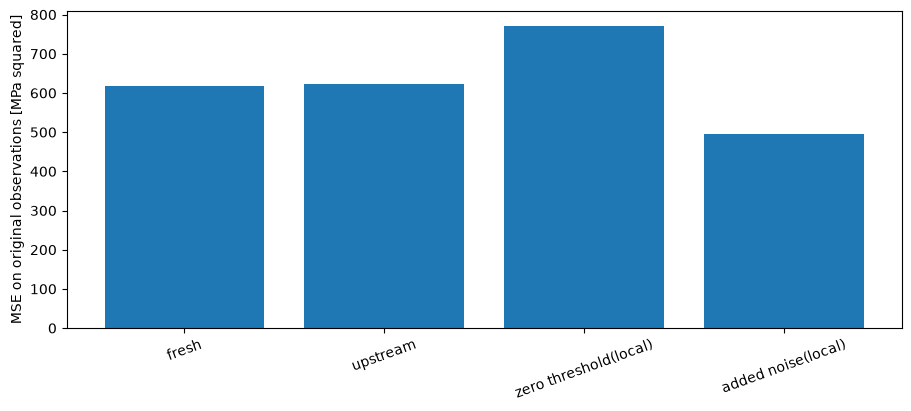

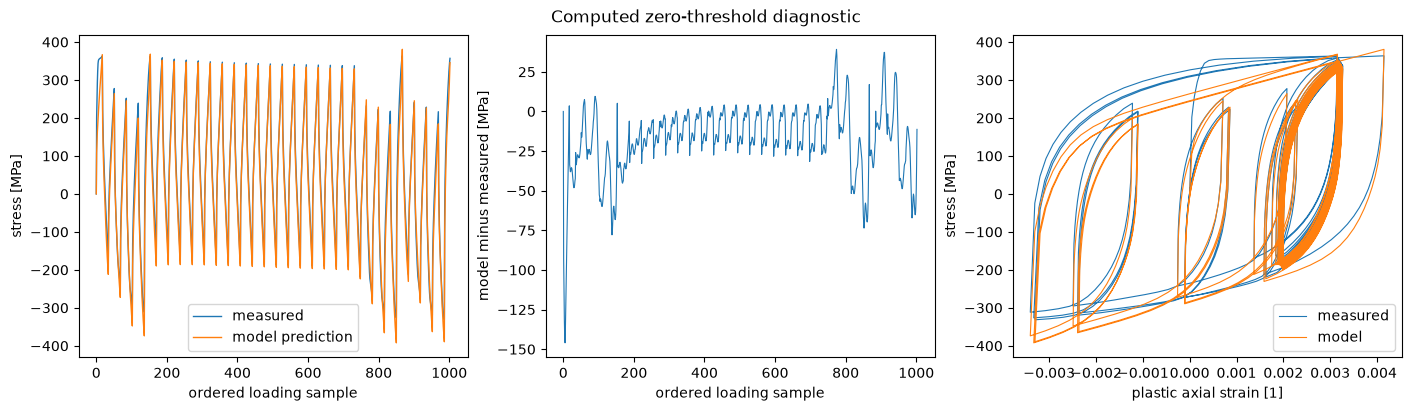

| Actually computed comparison | MSE against bound original stress (MPa squared) |
|---|---:|
| fresh full16starts | 617.225963186 |
| original full8starts | 621.758567266 |
| thresholdremoved localrefit | 770.211181181 |
| added3MPanoise localrefit | 494.368157722 |

In [5]:
from scipy.optimize import fmin
q0=fresh['parameters'][0].copy();eps=d['plastic_strain'];y=d['measured_stress']
def local_loss(q,target):
 if np.any(q<1e-5):return np.inf
 return float(np.mean((internal_states(q,eps)[2]-target)**2))
def no_threshold_loss(v):
 if np.any(v<1e-5):return np.inf
 return float(np.mean((internal_states(np.r_[v,0.],eps)[2]-y)**2))
qr=fmin(no_threshold_loss,q0[:-1],disp=False,maxiter=2500,maxfun=5000);qr=np.r_[qr,0.]
noisy=y+np.random.default_rng(501).normal(0,3.,len(y));qn=fmin(lambda q:local_loss(q,noisy),q0,disp=False,maxiter=2500,maxfun=5000)
def result_for(q):
 a,k,s=internal_states(q,eps);return dict(parameters=q[None],reconstruction=a[None],isotropic_stress=k[None])
reduced=result_for(qr);perturbed=result_for(qn);values=[mse(fresh),mse(upstream),mse(reduced),mse(perturbed)]
print(dict(zip(['fresh sixteen starts','author eight starts','threshold removed local refit','noisy observation local refit'],values)))
fig,ax=plt.subplots(figsize=(9,4),layout='constrained');ax.bar(range(4),values);ax.set_xticks(range(4),['fresh','upstream','zero threshold(local)','added noise(local)'],rotation=20);ax.set_ylabel('MSE on original observations [MPa squared]');plt.show()
show_fit(d,reduced,'Computed zero-threshold diagnostic');plt.show()
rows=['| Actually computed comparison | MSE against bound original stress (MPa squared) |','|---|---:|']
for name,value in zip(['fresh full16starts','original full8starts','thresholdremoved localrefit','added3MPanoise localrefit'],values):rows.append(f'| {name} | {value:.12g} |')
display(Markdown('\n'.join(rows)))


# 6. Evaluation and scientific limits
The standalone Judge verifies every reconstructed backstress and isotropic state from the submitted material parameters,then recombines the reported states and compares stress against all1003measurements. The objective accepts an equal or better physical fit without forcing one finite optimizer path. There is no independent internal-state or true-parameter ground truth. Positive parameters and the constitutive state equations condition this inverse solution. Limited uniaxial observations and multiple local minima restrict interpretation of individual hardening components. The selected classical benchmark does not claim the paper neural-network or tensor-train experiments were executed.

In [6]:
import subprocess
p=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding="utf8")
print(Path('output/judge_report.json').read_text(encoding="utf8"));assert p.returncode==0

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "stress_mse": 617.2259631864328,
    "backstress_model_error": 0.0,
    "isotropic_model_error": 0.0,
    "minimum_parameter": 0.017118823821242576
  },
  "thresholds": {
    "stress_mse": {
      "comparison": "<=",
      "boundary": 621.7591900244984
    },
    "backstress_model_error": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "isotropic_model_error": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "minimum_parameter": {
      "comparison": ">",
      "boundary": 0
    }
  },
  "errors": []
}


The noise-perturbed local refit reaches a lower MSE on the original observations (about 494 MPa²) than the standard finite 16-start search (about 617 MPa²). This diagnoses a different basin of the nonconvex objective and incomplete finite-search optimization. It does not show that adding noise improves physical accuracy, and this single perturbation is not a calibrated uncertainty estimate. The standard published-method budget and evaluation boundary remain unchanged.